# MSCA681 Tutorial 5: Decision trees

We will briefly explore classification trees (often referred to as CART, for Classification And Regression Trees).

A (binary) classification tree makes predictions by grouping similar observations and then assigning a probability to each group using the proportion of observations within that group that belong to the positive class. Groups can be thought of as nodes on a tree, and tree branches correspond to logical criteria on the predictor variables. There's a lot of neat math that goes into building the trees, but we won't get into that today.

We will use the `DecisionTreeClassifier` in `scikit-learn`.

## Preparing the data

To prepare our environment for today's session, we will begin by loading pandas, a core Python library for data analysis. Most of our machine learning work will be done using scikit-learn; we will load some additional libraries as we go through the session.

In [1]:
import pandas as pd
import numpy as np
import random
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Read the csv file
listings_df = pd.read_csv("listings_with_amenities.csv")
print(listings_df.shape)
# Display the first few rows of the DataFrame
listings_df.head()

(3585, 140)


,id,listing_url,scrape_id,last_scraped,name,summary,space,description,experiences_offered,neighborhood_overview,...,amenity_Other_pets,amenity_Washer___Dryer,amenity_Smoking_Allowed,amenity_Suitable_for_Events,amenity_Wheelchair_Accessible,amenity_Elevator_in_Building,amenity_Pool,amenity_Doorman,amenity_Paid_Parking_Off_Premises,amenity_Free_Parking_on_Street
0,12147973,https://www.airbnb.com/rooms/12147973,20160906204935,2016-09-07,Sunny Bungalow in the City,"Cozy, sunny, family home. Master bedroom high...",The house has an open and cozy feel at the sam...,"Cozy, sunny, family home. Master bedroom high...",none,"Roslindale is quiet, convenient and friendly. ...",...,0,0,0,0,0,0,0,0,0,0
1,3075044,https://www.airbnb.com/rooms/3075044,20160906204935,2016-09-07,Charming room in pet friendly apt,Charming and quiet room in a second floor 1910...,Small but cozy and quite room with a full size...,Charming and quiet room in a second floor 1910...,none,"The room is in Roslindale, a diverse and prima...",...,0,0,0,0,0,0,0,0,0,0
2,6976,https://www.airbnb.com/rooms/6976,20160906204935,2016-09-07,Mexican Folk Art Haven in Boston,"Come stay with a friendly, middle-aged guy in ...","Come stay with a friendly, middle-aged guy in ...","Come stay with a friendly, middle-aged guy in ...",none,The LOCATION: Roslindale is a safe and diverse...,...,0,0,0,0,0,0,0,0,0,0
3,1436513,https://www.airbnb.com/rooms/1436513,20160906204935,2016-09-07,Spacious Sunny Bedroom Suite in Historic Home,Come experience the comforts of home away from...,Most places you find in Boston are small howev...,Come experience the comforts of home away from...,none,Roslindale is a lovely little neighborhood loc...,...,0,0,0,0,0,0,0,0,0,0
4,7651065,https://www.airbnb.com/rooms/7651065,20160906204935,2016-09-07,Come Home to Boston,"My comfy, clean and relaxing home is one block...","Clean, attractive, private room, one block fro...","My comfy, clean and relaxing home is one block...",none,"I love the proximity to downtown, the neighbor...",...,0,0,0,0,0,0,0,0,0,0


In [3]:
# Print the list of columns in the DataFrame
print("Columns in the DataFrame:")
print(listings_df.columns)

Columns in the DataFrame:
Index(['id', 'listing_url', 'scrape_id', 'last_scraped', 'name', 'summary',
       'space', 'description', 'experiences_offered', 'neighborhood_overview',
       ...
       'amenity_Other_pets', 'amenity_Washer___Dryer',
       'amenity_Smoking_Allowed', 'amenity_Suitable_for_Events',
       'amenity_Wheelchair_Accessible', 'amenity_Elevator_in_Building',
       'amenity_Pool', 'amenity_Doorman', 'amenity_Paid_Parking_Off_Premises',
       'amenity_Free_Parking_on_Street'],
      dtype='object', length=140)


## Data exploration

Before moving forward, let's do some basic data cleaning.

In [4]:
# Replace the price column with a numeric version by removing $ and commas.
listings_df["price"] = listings_df["price"].replace({'\$': '', ',': ''}, regex=True).astype(float)
listings_df.loc[0:10, ["price", "name"]]

<>:2: SyntaxWarning: invalid escape sequence '\$'
<>:2: SyntaxWarning: invalid escape sequence '\$'
C:\Users\moeka\AppData\Local\Temp\ipykernel_13464\1152820713.py:2: SyntaxWarning: invalid escape sequence '\$'
  listings_df["price"] = listings_df["price"].replace({'\$': '', ',': ''}, regex=True).astype(float)


,price,name
0,250.0,Sunny Bungalow in the City
1,65.0,Charming room in pet friendly apt
2,65.0,Mexican Folk Art Haven in Boston
3,75.0,Spacious Sunny Bedroom Suite in Historic Home
4,79.0,Come Home to Boston
5,75.0,Private Bedroom + Great Coffee
6,100.0,New Lrg Studio apt 15 min to Boston
7,75.0,"""Tranquility"" on ""Top of the Hill"""
8,58.0,6 miles away from downtown Boston!
9,229.0,Perfect & Practical Boston Rental


Let's observe the price distribution and number of people who can be accommodated using seaborn:

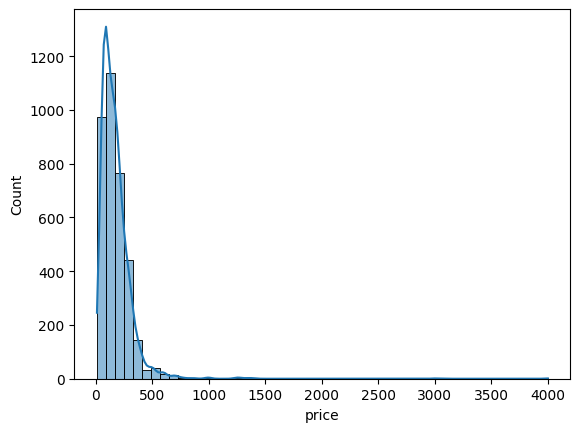

In [5]:
sns.histplot(listings_df["price"], bins=50, kde=True)
plt.show()

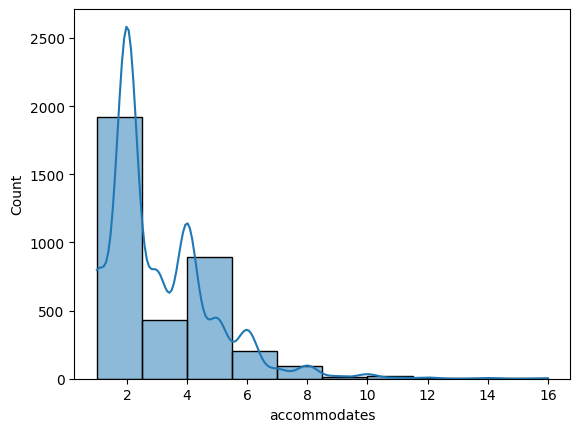

In [6]:
# distribution of the accommodates column
sns.histplot(listings_df["accommodates"], bins=10, kde=True)
plt.show()

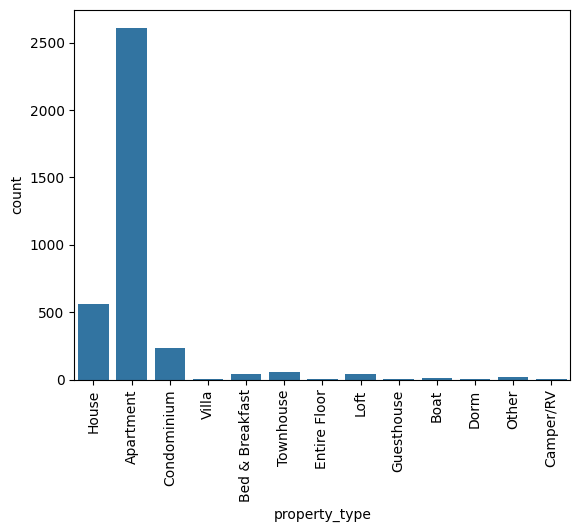

In [7]:
if "property_type" in listings_df.columns:
    # Distribution of property types
    sns.countplot(data=listings_df, x="property_type")
    plt.xticks(rotation=90)
    plt.show()

In [8]:
# We'll also clean up some outliers
listings_clean = listings_df.query('accommodates <= 10 & price <= 1000')
listings_clean = listings_clean.query('maximum_nights <= 2000')

# Filter by property type
property_types = ["Apartment", "House", "Condominium", "Townhouse", "Bed & Breakfast", "Loft"]
listings_clean = listings_clean[listings_clean["property_type"].isin(property_types)]
# filter to not include neighborhood_cleansed Leader District and Longwood Medical Area
listings_clean = listings_clean[~listings_clean["neighbourhood_cleansed"].isin(["Leather District", "Longwood Medical Area"])]    

# Find columns with sufficient fill (at most 25% missing values)
cols_keep = listings_clean.columns[listings_clean.isnull().mean() < 0.25]
# Keep only the columns with sufficient fill    
listings_clean = listings_clean[cols_keep]

# Let's one-hot encode our property types
listings_clean = pd.get_dummies(listings_clean, columns=["property_type"], drop_first = True, dtype = 'int')

# We're also going to filter to numeric columns for now-
# You can use one-hot encoding to handle categorical variables, but today we'll stick to this.
listings_clean = listings_clean.select_dtypes(include=[np.number, bool])

listings_clean.head(10)
print(cols_keep)

Index(['id', 'listing_url', 'scrape_id', 'last_scraped', 'name', 'summary',
       'description', 'experiences_offered', 'thumbnail_url', 'medium_url',
       ...
       'amenity_Other_pets', 'amenity_Washer___Dryer',
       'amenity_Smoking_Allowed', 'amenity_Suitable_for_Events',
       'amenity_Wheelchair_Accessible', 'amenity_Elevator_in_Building',
       'amenity_Pool', 'amenity_Doorman', 'amenity_Paid_Parking_Off_Premises',
       'amenity_Free_Parking_on_Street'],
      dtype='object', length=123)


## Seaborn examples

You can make a lot of fancy plots using seaborn!


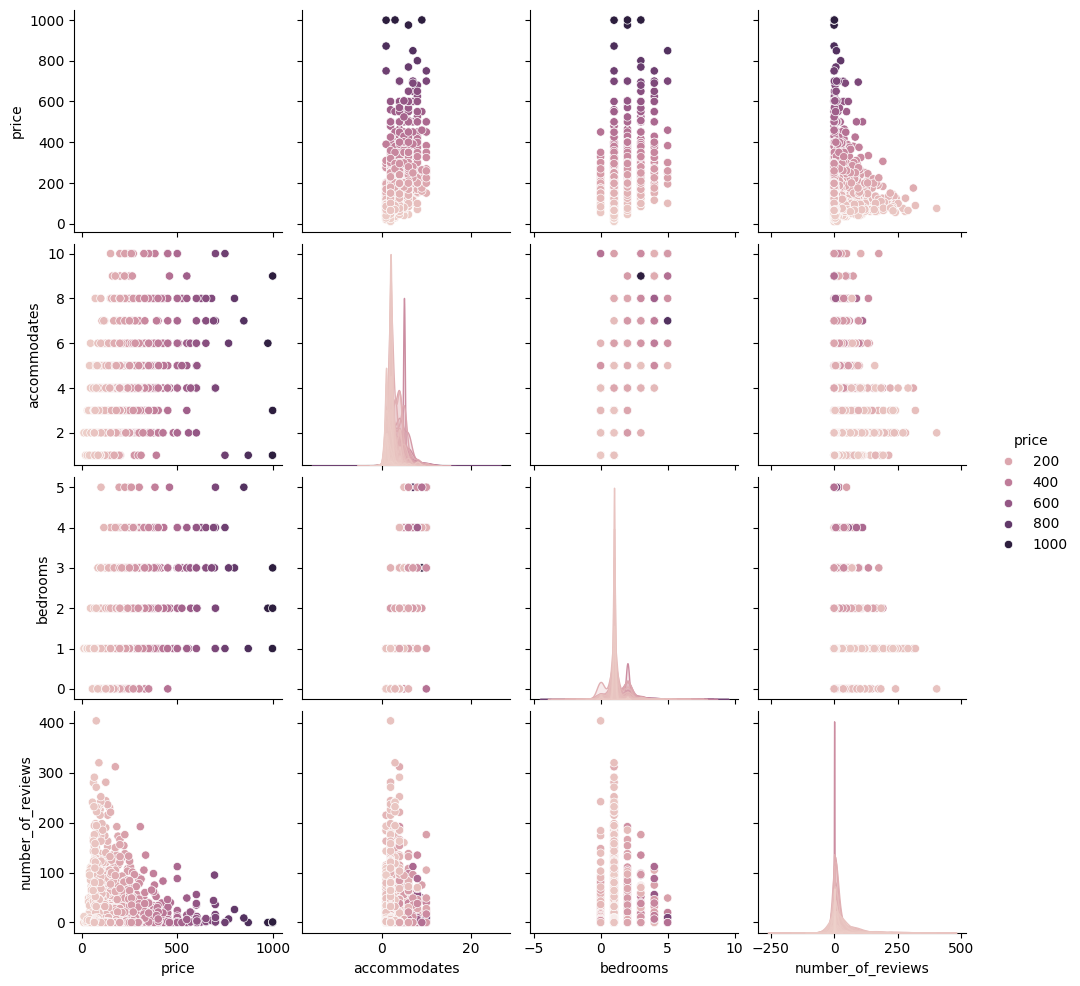

In [9]:
# seaborn pariplot to visualize relationship between price, accommodates, bedrooms and number of reviews.
sns.pairplot(listings_clean, vars=["price", "accommodates", "bedrooms", "number_of_reviews"], hue = "price")
plt.show()

C:\Users\moeka\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 86.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\moeka\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 93.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\moeka\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 79.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\moeka\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 82.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(ms

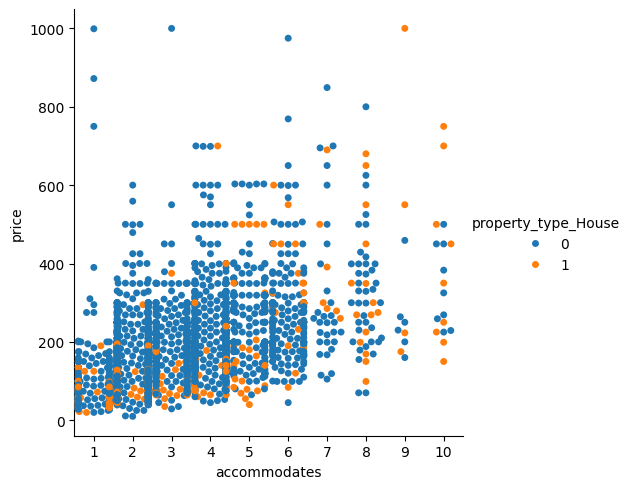

In [10]:
sns.catplot(data=listings_clean[['property_type_House', 'accommodates', 'price']], kind="swarm", x="accommodates", y="price", hue="property_type_House")
plt.show()

## Missing values
It is important to check for missing values in our target variable and handle it properly.

In [11]:
# Check missing values in the original target variable
print("Missing target values:", listings_clean['review_scores_rating'].isnull().sum())

# Check percentage of missing target values
print("Percentage missing:", listings_clean['review_scores_rating'].isnull().mean() * 100)

Missing target values: 778
Percentage missing: 22.234924264075453


22% of the listings have missing review rating; it is better to remove these observations.

In [12]:
# Remove observations with missing target values
listings_clean = listings_clean.dropna(subset=['review_scores_rating']).copy()

# Verify that no missing target values remain
print("Missing target values:", listings_clean['review_scores_rating'].isnull().sum())

print("Remaining observations:", len(listings_clean))

Missing target values: 0
Remaining observations: 2721


## Defining the regression/classification problem

We're going to use the Boston Airbnb dataset, where each entry is a property listing, and aim to use the input variables available to us in order to predict the price of a listing or do a classification based on a target variable. 

Note here that we haven't specified exactly which variables in the dataset will be used to define each $x_i$. This choice of feature space is part of the modeling process, and we will experiment with it.

## Training, Validation and Testing Splits

We want the model to generalise to unseen data.
To address this problem, we often split the dataset into three different chunks:

1. **Training data**: the data we build our models on.
1. **Validation data**: the data we tune hyperparameters on.
1. **Testing data**: the data we use to obtain a final estimate of performance.

The validation set is like an 'intermediate' estimate of performance. If we didn't use the validation set for this purpose, the only way of selecting the best model from a model class would be to look at its performance on the training set or the testing set.

`train_test_split` in `scikit-learn` provides an easy way of creating these data partitions. Let's start by just creating training/testing sets. We'll get to parameter tuning in a minute.

We will also stratify our split on this variable, meaning that the data is split to preserve the ratio of units with respect to the target variable in both the training and testing sets.


Let's impute the missing data - we will simply impute the most frequent value. There are other options available in `sklearn.impute`. Notice that the missingness is in numeric columns only, which makes it easier to deal with. If there are categoric columns with missing data, different approaches need to be taken (e.g. mode imputation).

In [13]:
from sklearn.model_selection import train_test_split


# define the target variable
# target = listings_clean['price'] # For the prediction task, we will use price as the target variable.
# Create a new column based on the review_scores_rating > 90 using np.where()
listings_clean['high_rating'] = np.where(listings_clean['review_scores_rating'] > 90, 1, 0)
target = listings_clean['high_rating']  # Now we will predict high_rating instead of price.

# define the features
features = listings_clean.columns.drop(['id', 'scrape_id', 'host_id', 'latitude', 'longitude',
                                                 'availability_30','availability_60', 'availability_90', 'availability_365',
                                                 'host_total_listings_count','calculated_host_listings_count',
                                                 #'price', 
                                                 'review_scores_rating', 'high_rating',
                                                 'review_scores_accuracy',
                                                 'review_scores_cleanliness', 'review_scores_checkin', 
                                                 'review_scores_communication', 'review_scores_location',
                                                 'review_scores_value', 'number_of_reviews', 'reviews_per_month'])

# Split the data into training and testing sets
# X_train, X_test, y_train, y_test = train_test_split(listings_clean_imputed[features], target, test_size=0.25, random_state=42)
# Split the data into training and testing with startifying 
X_train, X_test, y_train, y_test = train_test_split(listings_clean[features], target, test_size=0.25, random_state=42, stratify=target)

# Display the shapes of the training and testing sets
print("Training set shape:", X_train.shape, y_train.shape)
print("Testing set shape:", X_test.shape, y_test.shape)

Training set shape: (2040, 59) (2040,)
Testing set shape: (681, 59) (681,)


In [14]:
print(features)
print(X_train.columns)

Index(['host_listings_count', 'accommodates', 'bathrooms', 'bedrooms', 'beds',
       'price', 'guests_included', 'minimum_nights', 'maximum_nights',
       'amenity_TV', 'amenity_Wireless_Internet', 'amenity_Kitchen',
       'amenity_Free_Parking_on_Premises',
       'amenity_Pets_live_on_this_property', 'amenity_Dogs', 'amenity_Heating',
       'amenity_Family_Kid_Friendly', 'amenity_Washer', 'amenity_Dryer',
       'amenity_Smoke_Detector', 'amenity_Fire_Extinguisher',
       'amenity_Essentials', 'amenity_Shampoo',
       'amenity_Laptop_Friendly_Workspace', 'amenity_Internet',
       'amenity_Air_Conditioning', 'amenity_Pets_Allowed',
       'amenity_Carbon_Monoxide_Detector', 'amenity_Lock_on_Bedroom_Door',
       'amenity_Hangers', 'amenity_Hair_Dryer', 'amenity_Iron',
       'amenity_Cable_TV', 'amenity_First_Aid_Kit', 'amenity_Safety_Card',
       'amenity_other_49', 'amenity_other_50', 'amenity_Gym',
       'amenity_Breakfast', 'amenity_Indoor_Fireplace', 'amenity_Cats',
    

In [15]:
# Where are the missing values? (Training set)
missing_vals_train = X_train.isnull().sum()
# Display the columns with missing values
print("Training set:")
print(missing_vals_train.index[missing_vals_train>0])

# Where are the missing values? (Testing set)
missing_vals_test = X_test.isnull().sum()
# Display the columns with missing values
print("\nTesting set:")
print(missing_vals_test.index[missing_vals_test>0])

Training set:
Index(['bathrooms', 'bedrooms', 'beds'], dtype='object')

Testing set:
Index(['bathrooms'], dtype='object')


In [16]:
# Impute the missing values with the median of the column using sklearn's SimpleImputer 
from sklearn.impute import SimpleImputer

imp_median = SimpleImputer(missing_values=np.nan, strategy='median')
# Fit the imputer on the training set
imp_median.fit(X_train)
# Transform the training set
X_train_imputed = pd.DataFrame(imp_median.transform(X_train), columns=X_train.columns)

# Now, transform the testing set
X_test_imputed = pd.DataFrame(imp_median.transform(X_test), columns=X_test.columns)

Let's now observe our training data before training the models.

In [17]:
# summary of the training set
print("Training set summary:")
X_train.describe()

Training set summary:


,host_listings_count,accommodates,bathrooms,bedrooms,beds,price,guests_included,minimum_nights,maximum_nights,amenity_TV,...,amenity_Elevator_in_Building,amenity_Pool,amenity_Doorman,amenity_Paid_Parking_Off_Premises,amenity_Free_Parking_on_Street,property_type_Bed & Breakfast,property_type_Condominium,property_type_House,property_type_Loft,property_type_Townhouse
count,2040.000000,2040.000000,2030.000000,2033.000000,2034.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,...,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000
mean,44.695588,3.028922,1.200493,1.246926,1.598820,165.115686,1.448039,3.167647,801.453431,0.772059,...,0.208824,0.033824,0.061765,0.000980,0.001961,0.008824,0.064706,0.169608,0.012745,0.019118
std,141.217959,1.708430,0.442003,0.745737,1.010188,106.764955,1.039318,10.089853,483.935130,0.419607,...,0.406568,0.180819,0.240787,0.031304,0.044248,0.093541,0.246066,0.375380,0.112200,0.136972
min,1.000000,1.000000,0.000000,0.000000,0.000000,11.000000,0.000000,1.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,2.000000,1.000000,1.000000,1.000000,85.000000,1.000000,1.000000,180.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2.000000,2.000000,1.000000,1.000000,1.000000,147.000000,1.000000,2.000000,1125.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,7.000000,4.000000,1.000000,1.000000,2.000000,212.500000,2.000000,3.000000,1125.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,749.000000,10.000000,4.000000,5.000000,16.000000,1000.000000,14.000000,300.000000,2000.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


What do you remark? What should we do?



In [18]:
# Normally, we should normalize or standardize our data, so that features are on the same scale; however, this is unnecessary for tree-based models.

### The "manual" way ###

# Normalization
#X_train_normalized = (X_train - X_train.min())/(X_train.max()-X_train.min())
#X_test_normalized = (X_test - X_train.min())/(X_train.max()-X_train.min())

# Standardization
#X_train_standardized = (X_train - X_train.mean())/X_train.std()
#X_test_standardized = (X_test - X_train.mean())/X_train.std()


# The "sklearn" way
#from sklearn.preprocessing import StandardScaler, MinMaxScaler
# Create a scaler object
#std_scaler = StandardScaler()
# Fit the scaler on the training data
#std_scaler.fit(X_train_imputed)
# Transform the training and testing data
#X_train_standardized = std_scaler.transform(X_train_imputed)
#X_test_standardized = std_scaler.transform(X_test_imputed)
# Convert the standardized data back to a DataFrame
#X_train_standardized = pd.DataFrame(X_train_standardized, columns=X_train_imputed.columns)
# Convert the standardized testing set back to a DataFrame
#X_test_standardized = pd.DataFrame(X_test_standardized, columns=X_test_imputed.columns)

# Display the summary of the standardized training set  
#X_train_standardized.describe()

# Create a MinMaxScaler object
#minmax_scaler = MinMaxScaler()
# Fit the scaler on the training data
#minmax_scaler.fit(X_train_imputed)
# Transform the training and testing data
#X_train_normalized = minmax_scaler.transform(X_train_imputed)    
#X_test_normalized = minmax_scaler.transform(X_test_imputed)

# Convert the normalized data back to a DataFrame
#X_train_normalized = pd.DataFrame(X_train_normalized, columns=X_train_imputed.columns)
# Convert the normalized testing set back to a DataFrame
#X_test_normalized = pd.DataFrame(X_test_normalized, columns=X_test_imputed.columns)
# Display the summary of the normalized training set
#X_train_normalized.describe()

## Tuning the CART 

If we want to construct high accuracy decision tree models, then we need to tune the parameters. CART has many parameters that specify how the decision tree is constructed. Today we'll focus on `max_depth`, `criterion` and others.

* If the tree is too big => too many splits => we have an over-fitting problem.
* If the tree is too small => too few splits => we have an under-fitting problem.

We want to find a tree in the middle, that is "just right". We'll use `GridSearchCV` package to tune the tree depth using cross-validation. We'll also try out a couple of different criteria.



## Cross validation

We need a way of selecting the model with the best hyper-parameters for our task.

**Question**: How would we do this using the training/validation/testing splits?

**Answer**: Fit models on the training set, varying lambda. Then obtain an estimate of performance for each model on the validation set, and choose the best. Obtain a final estimate of performance for this model on the testing set.

Here, because `GridSearchCV` makes it easy, we're going to use a similar technique called cross-validation. Generally, we only consider this necessary when we're worried we have too little training data to obtain an accurate estimate of validation performance.

The idea behind cross-validation is: repeating the training/validation process multiple times provides us with several estimates of validation performance. Taking the average of these hopefully gives us an estimate which is less affected by noise.

To cross-validate, we start with only two partitions of the dataset:
1. Combined training/validation set: the data that we repeatedly train and validate on.
1. Testing set: the data we obtain our final performance estimate on.

But, how do we train and validate?

- First, select a number of *folds*.
- Then divide the training/validation data into this number of equal-sized partitions.
- For each fold, repeat the training/validation procedure. The fold is the validation data, and the other folds are training data.
- Average the performance of each model across folds and pick the hyperparameters which produce the best model.
- Fit a model on the entire training set using the selected values of hyperparameters.

In [19]:
# Import a Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier
# Import the GridSearchCV class
from sklearn.model_selection import GridSearchCV
# Create a Decision Tree Classifier
dt = DecisionTreeClassifier(random_state=42)
# Define the hyperparameters to tune
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': np.arange(3,10,1),
    'min_samples_split': [10, 15, 20],
    'min_samples_leaf': [5, 8, 10]
}

# Create a GridSearchCV object
gs = GridSearchCV(estimator=dt,
                  param_grid=param_grid, 
                  cv=5, 
                  return_train_score=True,
                  scoring= 'roc_auc',
                  n_jobs=-1, verbose=0)
# Fit the GridSearchCV object on the training data
random.seed(42)
gs.fit(X_train_imputed, y_train)
m_cart = gs.best_estimator_
# Display the best hyperparameters
print("Best hyperparameters:", gs.best_params_)

Best hyperparameters: {'criterion': 'entropy', 'max_depth': np.int64(9), 'min_samples_leaf': 8, 'min_samples_split': 20}


We can plot and save the resulting tree as follows:



In [20]:
from sklearn.tree import plot_tree

# Plot the decision tree
fig, axes = plt.subplots(nrows = 1,ncols = 1,figsize = (65,20), dpi=200)
plot_tree(m_cart, 
           feature_names=X_train.columns, 
           class_names=['Low', 'High'], 
           filled=False, 
           fontsize= 8) 
plt.title("Decision Tree for Predicting High Ratings")

# Save the decision tree plot
plt.savefig("decision_tree_high_rating.png", bbox_inches='tight', dpi=300)
plt.show()

In [21]:
import os
print(os.path.abspath("decision_tree_high_rating.png"))

C:\Users\moeka\AppData\Local\Programs\Python\Launcher\decision_tree_high_rating.png


## Evaluating the performance of the model

We can now explore out-of-sample performance. Ultimately, we want to predict whether or not a listing has high rating (>90) or low rating. 

However, classifer gives us something a bit different: a probability that each listing has high rating. This gives us flexibility in the way we predict. The most natural thing would be to predict that any listing with predicted probability above 0.5 has high rating, and any listing with predicted probability below 0.5 does not have high rating. But what if I want to be really confident that there's going to be a high rating listing? I may want to use a cutoff value of 0.9 rather than 0.5. In fact, we could choose any cutoff value and have a corresponding prediction model.

This is where AUC comes in. For every cutoff, we'll plot the false positive rate against the true positive rate and then take the area under this curve.

**Question**: As a sanity check: What is the true positive rate and false positive rate of a random classifier that chooses "has a high rating" with probability of $\alpha$? (i.e. a classifier that randomly predicts *positive* $\alpha$% of the time.) What is the AUC for this classifier?

**Answer**: Both the true positive rate and false positive rate are $\alpha$. The AUC is 0.5.

scikit-learn allows us to easily plot ROC curves and calculate AUC. Here's an example. We'll write our evaluation in a function so that we can evaluate other models in the same way.

Training ROC AUC score: 0.8330938821989037
Testing ROC AUC score: 0.6819494225408204


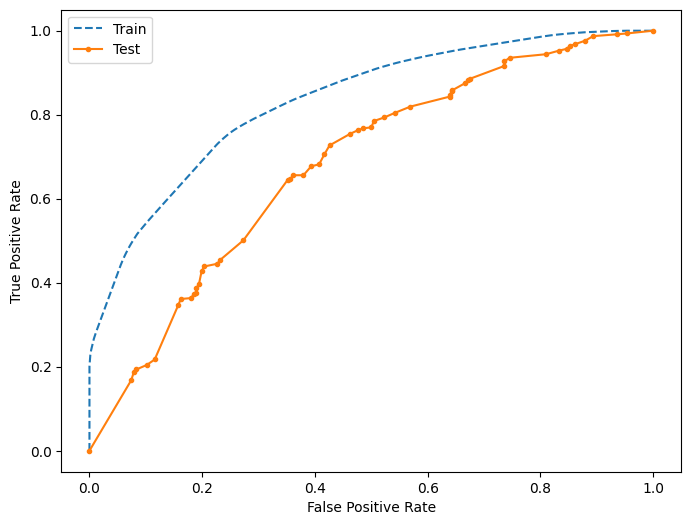

In [22]:
train_pred = m_cart.predict_proba(X_train_imputed)[:,1]
test_pred = m_cart.predict_proba(X_test_imputed)[:,1]

from sklearn.metrics import roc_auc_score, roc_curve
# Calculate the ROC AUC score for the training and testing sets
train_auc = roc_auc_score(y_train, train_pred)
test_auc = roc_auc_score(y_test, test_pred)
print("Training ROC AUC score:", train_auc)
print("Testing ROC AUC score:", test_auc)
# Plot the ROC curve for the training and testing sets
fpr_train, tpr_train, _ = roc_curve(y_train, train_pred)
fpr_test, tpr_test, _ = roc_curve(y_test, test_pred)

plt.figure(figsize=(8, 6))
plt.plot(fpr_train, tpr_train, linestyle='--', label='Train')
plt.plot(fpr_test, tpr_test, marker='.', label='Test')
# axis labels
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
# show the legend
plt.legend()
# show the plot
plt.show()

We can also look at threshold-based metrics. By selecting a decision threshold $t$, we predict all observations with a predicted probability $\hat{y} \geq t$ to have a high rating and all others to have a low rating.

Let's calculate the training and testing accuracy for our model:

In [23]:
from sklearn.metrics import confusion_matrix, accuracy_score
t = 0.5
print("Train Accuracy: %.3f" %  accuracy_score(y_train, train_pred > t))
print("Test Accuracy: %.3f" %  accuracy_score(y_test, test_pred > t))

# If we wanted to get all of the elements of the confusion matrix, we could pull them like this:
tn, fp, fn, tp = confusion_matrix(y_train, train_pred > t).ravel()

Train Accuracy: 0.776
Test Accuracy: 0.696


Before we move on, we'll wrap all of our evaluation steps into a function that we can use to evaluate other models in a consistent way.

In [24]:
# define a classification_evaluation function(model, X_train, y_train, X_test, y_test, threshold=0.5):
def classification_evaluation(model, X_train, y_train, X_test, y_test, threshold=0.5):
    from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score, f1_score

    train_pred = model.predict_proba(X_train)[:, 1]
    test_pred = model.predict_proba(X_test)[:, 1]
    
    train_auc = roc_auc_score(y_train, train_pred)
    test_auc = roc_auc_score(y_test, test_pred)
    
    fpr_train, tpr_train, _ = roc_curve(y_train, train_pred)
    fpr_test, tpr_test, _ = roc_curve(y_test, test_pred)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr_train, tpr_train, linestyle='--', label='Train')
    plt.plot(fpr_test, tpr_test, marker='.', label='Test')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend()
    plt.show()

    print("Training ROC AUC score:", train_auc)
    print("Testing ROC AUC score:", test_auc)
    print("Train Accuracy: %.3f" % accuracy_score(y_train, train_pred > threshold))
    print("Test Accuracy: %.3f" % accuracy_score(y_test, test_pred > threshold))
    # report precision, recall and f1 score for the training and testing sets
    print("Train Precision: %.3f" % precision_score(y_train, train_pred > threshold))   
    print("Test Precision: %.3f" % precision_score(y_test, test_pred > threshold))
    print("Train Recall: %.3f" % recall_score(y_train, train_pred > threshold)) 
    print("Test Recall: %.3f" % recall_score(y_test, test_pred > threshold))
    print("Train F1 Score: %.3f" % f1_score(y_train, train_pred > threshold))
    print("Test F1 Score: %.3f" % f1_score(y_test, test_pred > threshold))

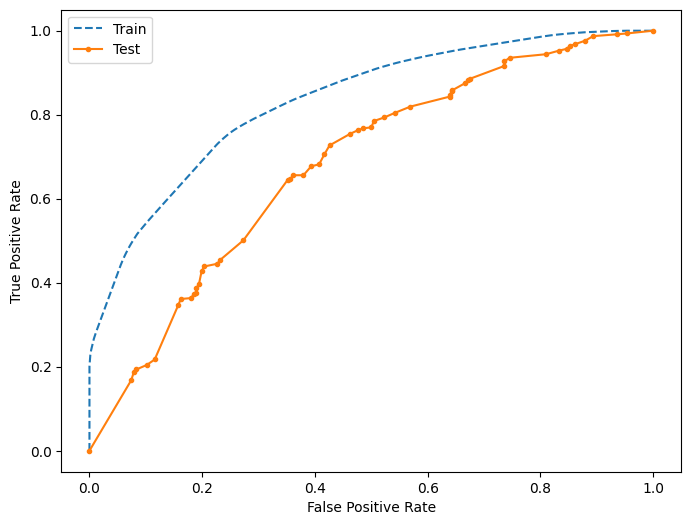

Training ROC AUC score: 0.8330938821989037
Testing ROC AUC score: 0.6819494225408204
Train Accuracy: 0.776
Test Accuracy: 0.696
Train Precision: 0.808
Test Precision: 0.756
Train Recall: 0.881
Test Recall: 0.819
Train F1 Score: 0.843
Test F1 Score: 0.786


In [25]:
classification_evaluation(m_cart, X_train_imputed, y_train, X_test_imputed, y_test, threshold=0.5)

## Random forest

We will briefly take a look at random forests, using the [RandomForestClassifier()](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html). A random forest is a collection of slightly randomized decision trees (hence the name "forest"), and can be used for classification or prediction. They often have excellent predictive performance, but can be expensive to train and lack interpretability. Random forests have many hyperparameters that can be tuned to achieve the best possible predictive performance. Perhaps the most important hyperparameter is the number of trees to include in the forest. More trees results in a longer training time but can improve prediction and decrease overfitting.
The goal of Random Forest is to train a pool of base tree learners with a high variance but a small bias. They are not necessarily weak learners!
With bagging, we explicitly train weaker (but not necessarily weak) learners.


Let's start by training a random forest model for a classification task. We will perform the same task of predicting whether or not a listing has a high review rating, using price and neighborhood as predictors (dropping other review related features too). We will compare the performance of random forest to what we got using our simple CART model. We'll use a grid search to tune the number of estimators.

Note: This will take a few minutes!


In [26]:
from sklearn.ensemble import RandomForestClassifier
# import the grid search class
from sklearn.model_selection import GridSearchCV

# define the hyperparameters to tune
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': np.arange(3, 10, 1),
    'min_samples_leaf': [0.01, 0.02],
    'max_features': [0.1, 0.5, 0.8, 'sqrt', 'log2'],
    'criterion': ['gini', 'entropy']
}

# Create a Random Forest Classifier
rf = RandomForestClassifier(random_state=42, n_jobs=-1)
# Create a GridSearchCV object
gs = GridSearchCV(estimator=rf,
                     param_grid=param_grid_rf, 
                     cv=5, 
                     return_train_score=True,
                     scoring='roc_auc',
                     n_jobs=-1, verbose=0)

# Fit the GridSearchCV object on the training data
random.seed(42) 
gs.fit(X_train_imputed, y_train)
m_rf = gs.best_estimator_
print("Best parameters: ", gs.best_params_)

Best parameters:  {'criterion': 'entropy', 'max_depth': np.int64(7), 'max_features': 0.8, 'min_samples_leaf': 0.01, 'n_estimators': 300}


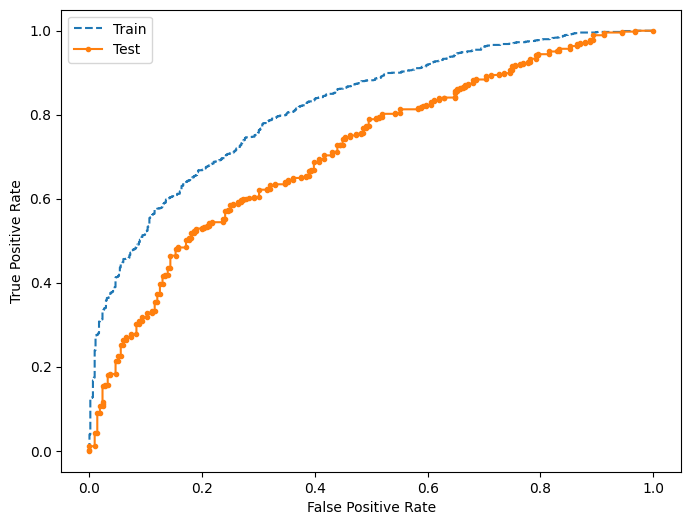

Training ROC AUC score: 0.8172779224577102
Testing ROC AUC score: 0.7118777379530068
Train Accuracy: 0.755
Test Accuracy: 0.703
Train Precision: 0.756
Test Precision: 0.723
Train Recall: 0.946
Test Recall: 0.918
Train F1 Score: 0.840
Test F1 Score: 0.809


In [27]:
# Let's evaluate the model performance
classification_evaluation(m_rf, X_train_imputed, y_train, X_test_imputed, y_test)

The tuned random forest model improves on the CART model. In general, random forests give stronger performance than single decision trees, but there is a sacrifice in interpretability.  The prediction accuracy is now much better, and it doesn't look we are overfitting too much. It would likely be even better if the other hyperparameters of the random forest model were properly tuned! (What are hyperparameters you can tune?)

## Boosted trees

Boosting means combining a learning algorithm in series to achieve a strong learner from many sequentially connected weak learners. In case of gradient boosted decision trees algorithm, the weak learners are decision trees.

Each tree attempts to minimize the errors of the previous trees. Trees in boosting are weak learners but adding many trees in series and each focusing on the errors from previous one make boosting a highly efficient and accurate model.

A major difference between random forests and boosting algorithms is the overall size of the trees. In a random forest, we tend to choose trees as strong learners — they would do just fine as a decision tree on their own. In boosting algorithms, trees are artificially limited to very shallow depths (in practice rarely more than depth 5), to ensure that each model is only slightly better than random chance.

We'll start with the famous XGBoost, maybe the most widely used machine learning model!

In [28]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\moeka\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [29]:
import xgboost as xgb 
import time
from sklearn.model_selection import GridSearchCV

# Define the parameter grid
param_grid = {
    'n_estimators': [100, 200, 300],
     'max_depth': np.arange(2,6,1),
}

# Create a grid search object
gs = GridSearchCV(estimator= xgb.XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss'),
                      param_grid=param_grid,
                      cv=5,
                      return_train_score=True,
                      scoring='roc_auc',
                      n_jobs=-1, verbose=0)

## Fit the model
random.seed(1)
start_time = time.time()
gs.fit(X_train_imputed, y_train)
print("--- %s seconds ---" % (time.time() - start_time))

m_xgb = gs.best_estimator_
print("Best parameters: ", gs.best_params_)

--- 6.451800346374512 seconds ---
Best parameters:  {'max_depth': np.int64(2), 'n_estimators': 100}


C:\Users\moeka\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [09:10:33] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


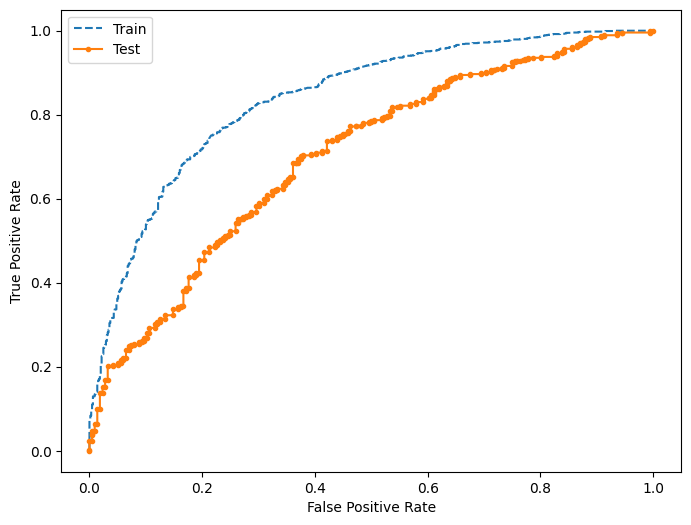

Training ROC AUC score: 0.8376814853133561
Testing ROC AUC score: 0.7023197929111907
Train Accuracy: 0.781
Test Accuracy: 0.717
Train Precision: 0.785
Test Precision: 0.748
Train Recall: 0.936
Test Recall: 0.882
Train F1 Score: 0.854
Test F1 Score: 0.809


In [30]:
# Evaluate the model performance
classification_evaluation(m_xgb, X_train_imputed, y_train, X_test_imputed, y_test)

In [31]:
# create a boosting classfier from sklearn
from sklearn.ensemble import GradientBoostingClassifier

# Define the parameter grid for Gradient Boosting
param_grid_gb = {
    'n_estimators': [100, 200, 300],
    'max_depth': np.arange(2, 6, 1),
    'learning_rate': [0.01, 0.1, 0.2]
}

# Create a grid search object for Gradient Boosting
gs = GridSearchCV(estimator=GradientBoostingClassifier(random_state=42),
                     param_grid=param_grid_gb,
                     cv=5,
                     return_train_score=True,
                     scoring='roc_auc',
                     n_jobs=-1, verbose=0)

# Fit the model
random.seed(1)
start_time = time.time()
gs.fit(X_train_imputed, y_train)
print("--- %s seconds ---" % (time.time() - start_time))
m_gb = gs.best_estimator_
print("Best parameters: ", gs.best_params_)

--- 47.74965000152588 seconds ---
Best parameters:  {'learning_rate': 0.1, 'max_depth': np.int64(2), 'n_estimators': 200}


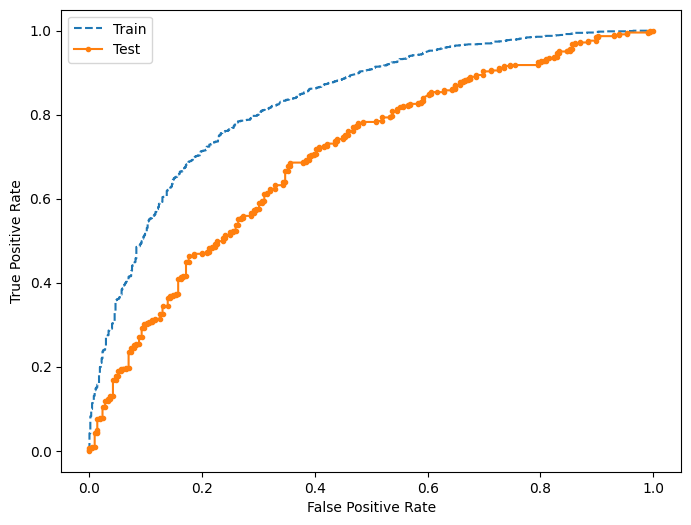

Training ROC AUC score: 0.83077266468681
Testing ROC AUC score: 0.7016925527678215
Train Accuracy: 0.775
Test Accuracy: 0.706
Train Precision: 0.776
Test Precision: 0.734
Train Recall: 0.943
Test Recall: 0.895
Train F1 Score: 0.851
Test F1 Score: 0.806


In [32]:
# Evaluate the model performance
classification_evaluation(m_gb, X_train_imputed, y_train, X_test_imputed, y_test)

LightGBM, short for Light Gradient Boosting Machine, is another distributed gradient boosting framework originally developed by Microsoft. Light GBM uses leaf-wise splitting over depth-wise splitting which enables it to converge much faster but also leads to a higher tendency to overfit.

In [33]:
pip install lightgbm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\moeka\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [34]:
import lightgbm as lgb

# Define the parameter grid
param_grid = {
    'n_estimators': [100, 200, 300],
     'max_depth': np.arange(2,6,1),
}

# Define the parameters for the model
gs = GridSearchCV(lgb.LGBMClassifier(random_state=42, verbose = -1),
                  return_train_score=True,
                  param_grid=param_grid,
                  scoring='roc_auc',
                  cv=5, verbose = 0)

## Fit the model
random.seed(1)

start_time = time.time()
gs.fit(X_train_imputed, y_train)
print("--- %s seconds ---" % (time.time() - start_time))

m_lgb = gs.best_estimator_
print("Best parameters: ", gs.best_params_)

--- 14.989490270614624 seconds ---
Best parameters:  {'max_depth': np.int64(2), 'n_estimators': 200}


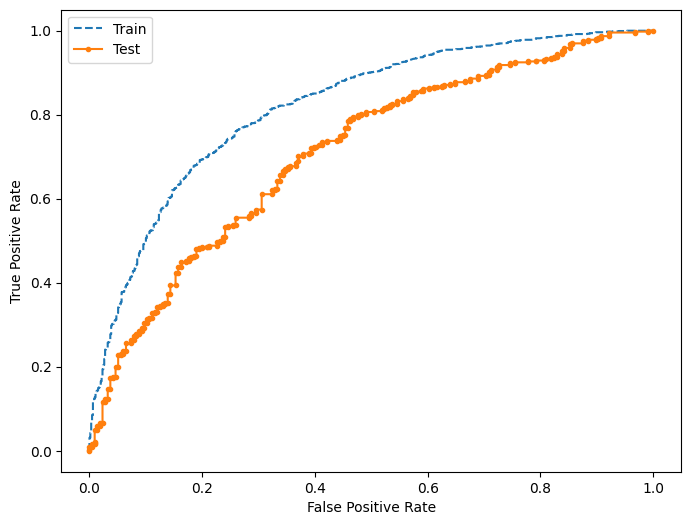

Training ROC AUC score: 0.8204415574920882
Testing ROC AUC score: 0.7109518120270809
Train Accuracy: 0.770
Test Accuracy: 0.706
Train Precision: 0.772
Test Precision: 0.735
Train Recall: 0.940
Test Recall: 0.892
Train F1 Score: 0.848
Test F1 Score: 0.806


In [35]:
classification_evaluation(m_lgb, X_train, y_train, X_test, y_test)

### Interpreting Random Forest and Boosted-Tree Models

Although random forest and boosted-tree models are not very interpretable and hard to visualize, there is a popular method called variable importance that is commonly used. We will use the built-in `feature_importances_` from these models. This tells us which variables the random forest or boosted-tree model has determined as the most important for predicting whether or not a listing contains high rating. It uses Gini importance, which is the mean decrease in node impurity (you can read more about this metric online), to rank the importance of all of the predictors used in the model. There are other metrics besides the Gini Importance that can also be used as a metric.

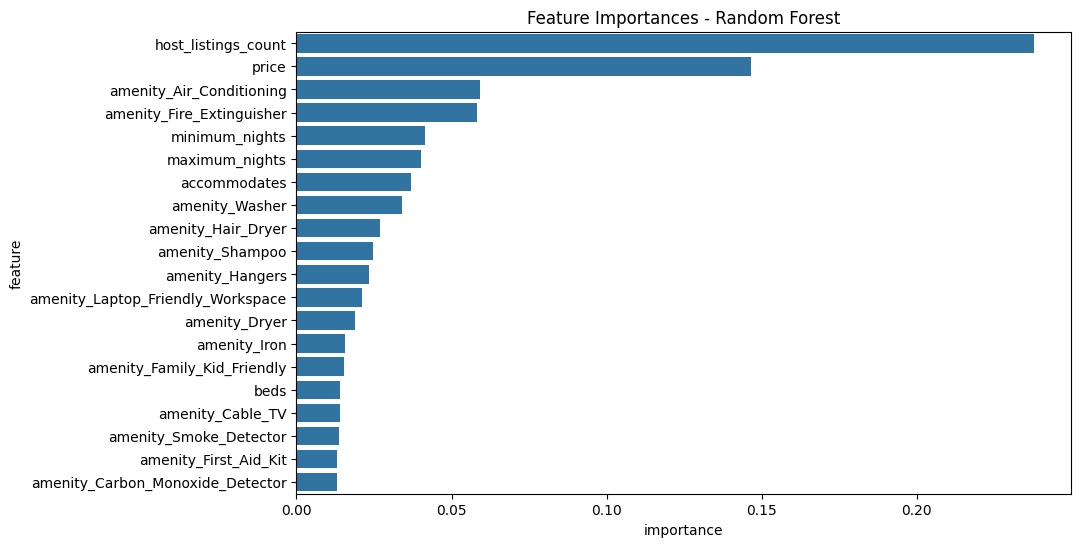

In [36]:
# Create a feature importance for the random forest model
importances = m_rf.feature_importances_
# Create a DataFrame for the feature importances
feature_importances_rf = pd.DataFrame({'feature': X_train_imputed.columns, 'importance': importances})
# Sort the DataFrame by importance
feature_importances_rf = feature_importances_rf.sort_values(by='importance', ascending=False)
# Plot the feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feature_importances_rf.head(20))
plt.title('Feature Importances - Random Forest')
plt.show()

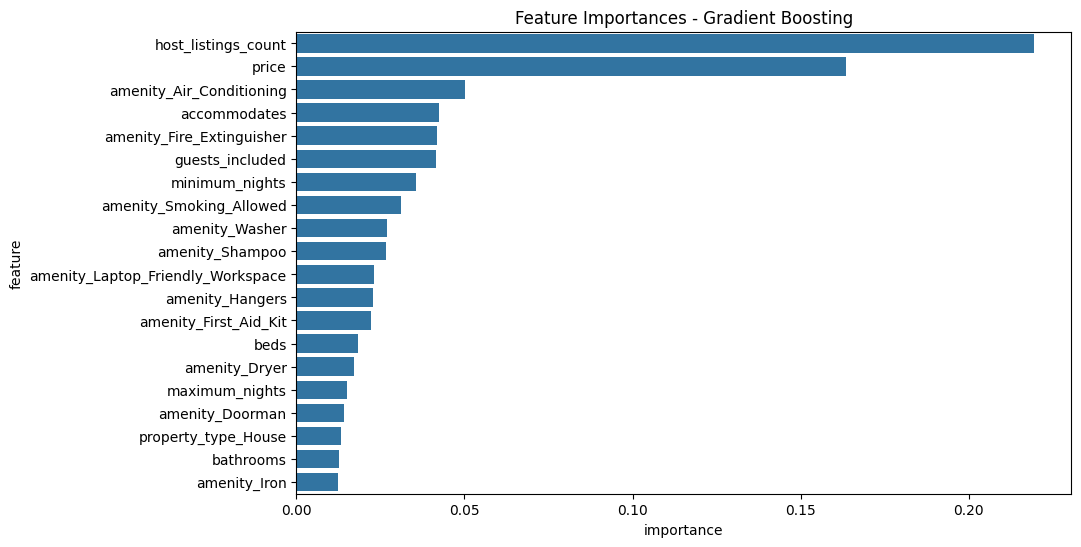

In [37]:
# Feature importance for the gradient boosting model
importances_gb = m_gb.feature_importances_
# Create a DataFrame for the feature importances
feature_importances_gb = pd.DataFrame({'feature': X_train_imputed.columns, 'importance': importances_gb})   
# Sort the DataFrame by importance
feature_importances_gb = feature_importances_gb.sort_values(by='importance', ascending=False)
# Plot the feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feature_importances_gb.head(20))
plt.title('Feature Importances - Gradient Boosting')
plt.show()

### Exercise: Get a better boosted-tree model!

In practice, we can use a more thorough gridsearch on other hyperparameters such as learning rate, min_sample_by_leaf, etc.

Check the documentation of LightGBM and try to see if you can find a better combination of hyperparameters by exploring the different possibilities!
- Documentation: https://lightgbm.readthedocs.io/en/latest/pythonapi/lightgbm.LGBMClassifier.html
- Advice on parameter tuning for LightGBM: https://lightgbm.readthedocs.io/en/latest/Parameters-Tuning.html#for-better-accuracy